# RQ2 TIB: sample-size and coverage EDA

Historical 20/70 Lecture-cohort analysis. The current TIB scope is every pinned `train`, `valid`, and `test` record regardless of genre; do not extrapolate these scores or sample-size estimates to it.

Executed locally on the pinned `valid` diagnostic cohort and the extracted Qwen v2 automatic-evaluation receipt (source ZIP SHA-256 `2b9c5a80f3c6b16eb72357f7bdb1a41c86f904ef9f11a9bf451fccea3d73ccc7`). This estimates **ROUGE-L precision for planning**, not statistical power for factuality or proof that S3 is better. No test split is read. The new chat-prompt recipe has different outputs, so v2 variance is provisional.

In [1]:
import hashlib, json, math, statistics
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

def find_repo(start):
    for parent in (start, *start.parents):
        if (parent / 'experiments/scripts/rq2-tib-valid-eda.py').exists():
            return parent
    raise FileNotFoundError('Run from inside the nested multimodal-lecture-summarizer repository')

ROOT = find_repo(Path.cwd().resolve())
RECEIPT = ROOT / 'plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-diagnostic-receipt.json'
ELIGIBLE = ROOT / 'plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-eligible-metadata.json'
EVALUATION = ROOT / 'plans/261002-0946-rq2-controlled-summarization/rq2-v2-automatic-evaluation.json'
receipt = json.loads(RECEIPT.read_text(encoding='utf-8'))
eligible_snapshot = json.loads(ELIGIBLE.read_text(encoding='utf-8'))
evaluation_bytes = EVALUATION.read_bytes()
assert hashlib.sha256(evaluation_bytes).hexdigest() == 'd65bf94ce198c52a093433bd62583542e3b96476f9587afb63ba843ce78552f9'
evaluation = json.loads(evaluation_bytes)
assert receipt['revision'] == evaluation['revision']
assert receipt['selected_doi_sha256'] == evaluation['selection_sha256']
assert eligible_snapshot['dataset'] == receipt['dataset']
assert eligible_snapshot['revision'] == receipt['revision']
assert eligible_snapshot['split'] == 'valid' and not eligible_snapshot['test_content_accessed']
assert eligible_snapshot['selection_sha256'] == receipt['selected_doi_sha256']
selected = pd.DataFrame(receipt['selected'])
eligible = pd.DataFrame(eligible_snapshot['records'])
scores = pd.DataFrame(evaluation['rows'])
assert len(selected) == len(scores) == 20
assert len(eligible) == eligible_snapshot['eligible_count'] == receipt['candidate_count'] == 70
assert eligible.doi.is_unique and set(selected.doi) <= set(eligible.doi)
assert set(selected.doi) == set(scores.doi)
assert (scores.status == 'completed').all()
eligible['author_key'] = eligible.author.map(lambda value: ' '.join(str(value).casefold().split()))
assert eligible.author_key.ne('').all()
eligible['doi_hash'] = eligible.doi.map(lambda value: hashlib.sha256(value.encode()).hexdigest())
one_per_author = eligible.sort_values(['doi_hash', 'doi']).drop_duplicates('author_key').copy()
assert len(one_per_author) == 52
assert set(selected.doi) <= set(one_per_author.doi)
print('Revision:', receipt['revision'], '| split:', receipt['split_read'])
print('All valid:', receipt['source_count'], '| exact Lecture:', receipt['lecture_count'],
      '| structurally eligible:', len(eligible), '| unique authors:', len(one_per_author),
      '| selected:', len(selected))
print('Selection:', receipt['selection'])
print('V2 evaluation SHA-256:', hashlib.sha256(evaluation_bytes).hexdigest())

Revision: e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee | split: valid
All valid: 910 | exact Lecture: 71 | structurally eligible: 70 | unique authors: 52 | selected: 20
Selection: SHA-256 DOI order, first 20 validation Lecture records with DOI, source URL and ordered timed transcript, one record per exact normalized author string; license is not an eligibility gate
V2 evaluation SHA-256: d65bf94ce198c52a093433bd62583542e3b96476f9587afb63ba843ce78552f9


## What the 20 cases cover

The original selector chose the first 20 eligible DOI hashes with one normalized author per item. It did not stratify by `subject`, length, or abstract quality. The executed export now includes metadata for all 70 structurally eligible talks. A deterministic one-per-author extension contains 52 talks and retains the original 20. This is a candidate cohort, not a frozen formal endpoint. The existing abstract screen is a provisional editorial screen, not verified ground truth.

Subject distribution: eligible vs author-distinct extension vs original 20


,eligible_70,one_author_52,selected_20,eligible_pct,selected_pct
subject,,,,,
Chemistry,19,12,4,27.1,20.0
Physics,15,7,2,21.4,10.0
Linguistics,11,10,4,15.7,20.0
Mathematics\nPhysics,10,9,4,14.3,20.0
Mathematics,7,7,2,10.0,10.0
Architecture,3,2,2,4.3,10.0
Engineering,3,3,0,4.3,0.0
Computer Science\nMathematics,2,2,2,2.9,10.0


Subject × provisional abstract screen:


reference_screen,candidate_unverified,unsuitable
subject,,
Architecture,1,1
Chemistry,1,3
Computer Science\nMathematics,2,0
Linguistics,4,0
Mathematics,2,0
Mathematics\nPhysics,1,3
Physics,1,1


Abstract screen totals: {'candidate_unverified': 12, 'unsuitable': 8}
eligible_70 short abstracts 23 / 70 | words median 7920 | words max 20409 | duration median min 66.7
one_author_52 short abstracts 21 / 52 | words median 7920 | words max 20409 | duration median min 64.8
selected_20 short abstracts 9 / 20 | words median 7881 | words max 12131 | duration median min 62.4


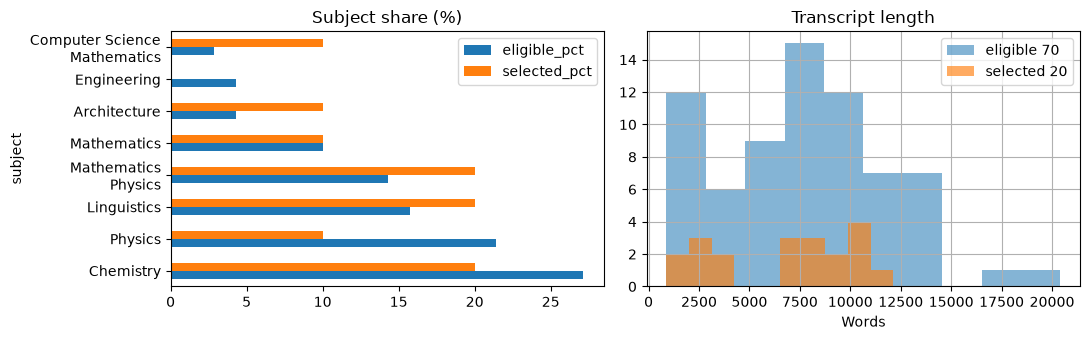

In [2]:
SCREEN = ROOT / 'plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-reference-screen.json'
screen = json.loads(SCREEN.read_text(encoding='utf-8'))
assert screen['revision'] == receipt['revision'] and screen['split'] == 'valid'
selected['doi_id'] = selected.doi.str.extract(r'/(\d+)')[0]
selected['reference_screen'] = selected.doi_id.map(lambda d: screen['items'][d]['screen'])
subjects = pd.concat([eligible.subject.value_counts().rename('eligible_70'),
                      one_per_author.subject.value_counts().rename('one_author_52'),
                      selected.subject.value_counts().rename('selected_20')], axis=1).fillna(0).astype(int)
subjects.index.name = 'subject'
subjects['eligible_pct'] = 100 * subjects.eligible_70 / len(eligible)
subjects['selected_pct'] = 100 * subjects.selected_20 / len(selected)
print('Subject distribution: eligible vs author-distinct extension vs original 20')
display(subjects.round(1))
print('Subject × provisional abstract screen:')
display(pd.crosstab(selected.subject, selected.reference_screen))
print('Abstract screen totals:', selected.reference_screen.value_counts().to_dict())
for name, frame in [('eligible_70', eligible), ('one_author_52', one_per_author), ('selected_20', selected)]:
    print(name, 'short abstracts', int((frame.abstract_words < 30).sum()), '/', len(frame),
          '| words median', int(frame.transcript_words.median()),
          '| words max', int(frame.transcript_words.max()),
          '| duration median min', round(frame.duration_minutes.median(), 1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
subjects[['eligible_pct', 'selected_pct']].plot.barh(ax=axes[0], title='Subject share (%)')
eligible.transcript_words.hist(ax=axes[1], bins=10, alpha=.55, label='eligible 70')
selected.transcript_words.hist(ax=axes[1], bins=10, alpha=.65, label='selected 20')
axes[1].legend(); axes[1].set(title='Transcript length', xlabel='Words')
fig.tight_layout(); plt.show()

## Paired-score variability and precision scenarios

The unit is a DOI pair, with delta = S3 minus S1 ROUGE-L. The table uses `1.96 × pilot SD / sqrt(n)` as a **planning approximation** to a 95% half-width. It assumes future independent talks have similar delta variance; that assumption has not been validated. It does not repair noisy abstracts.

Observed n: 20 | mean delta: -0.00643 | SD: 0.03599
Saved paired-bootstrap 95% CI: [-0.02125, 0.00946]
S3 / S1 / tie: 9 / 10 / 1


,n,approx_95pct_half_width
0,20,0.01577
1,30,0.01288
2,40,0.01115
3,50,0.00998
4,52,0.00978
5,60,0.00911
6,70,0.00843


Target ±0.010 ROUGE-L -> about 50 independent pairs under v2 variance
Target ±0.005 ROUGE-L -> about 200 independent pairs under v2 variance


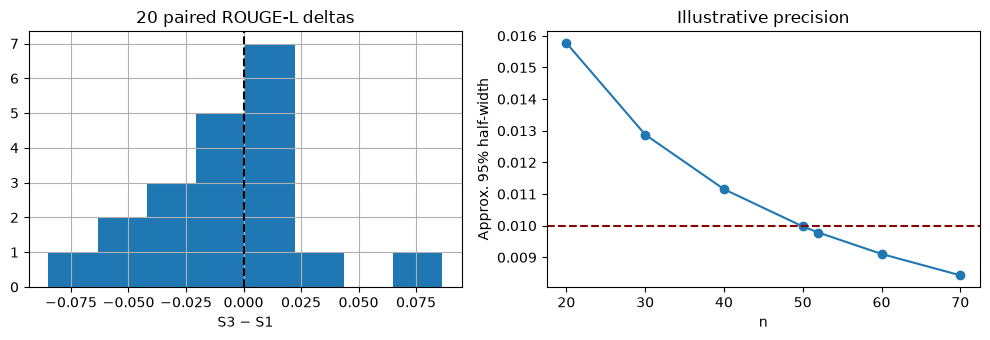

In [3]:
delta = scores.delta_S3_minus_S1.astype(float)
sd = statistics.stdev(delta)
mean = statistics.mean(delta)
ci = evaluation['paired_rouge']['ci95']
print('Observed n:', len(delta), '| mean delta:', round(mean, 5), '| SD:', round(sd, 5))
print('Saved paired-bootstrap 95% CI:', [round(x, 5) for x in ci])
print('S3 / S1 / tie:', int((delta > 0).sum()), '/', int((delta < 0).sum()), '/', int((delta == 0).sum()))
scenarios = pd.DataFrame([{'n': n, 'approx_95pct_half_width': 1.96 * sd / math.sqrt(n)}
                          for n in [20, 30, 40, 50, 52, 60, 70]])
display(scenarios.round(5))
for width in [0.01, 0.005]:
    needed = math.ceil((1.96 * sd / width) ** 2)
    print(f'Target ±{width:.3f} ROUGE-L -> about {needed} independent pairs under v2 variance')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
delta.hist(ax=axes[0], bins=8); axes[0].axvline(0, color='black', linestyle='--')
axes[0].set(title='20 paired ROUGE-L deltas', xlabel='S3 − S1')
scenarios.plot(x='n', y='approx_95pct_half_width', marker='o', ax=axes[1], legend=False)
axes[1].axhline(0.01, color='darkred', linestyle='--')
axes[1].set(title='Illustrative precision', ylabel='Approx. 95% half-width')
fig.tight_layout(); plt.show()

## Decision and missing evidence

- **20** is justified as a deterministic development diagnostic, not a representative research sample. It misses Engineering entirely, includes only 2 of 15 Physics talks, and does not include the eligible set's longest talks (20,409 versus 12,131 words).
- Under v2 ROUGE-L variability, **about 50 independent pairs** would give an approximate 95% half-width of ±0.01. The deterministic **52 distinct-author** candidate set covers all eight observed subject tags and gives about ±0.0098; all **70 talks** would give about ±0.0084 only if they were independent. These are planning figures, not mandatory cutoffs. At ±0.005, the approximation needs about 200 pairs, more than the 70 structurally eligible exact-Lecture talks.
- The selected 20 used a raw-prompt, 96/384-token recipe; the chat pilot changed prompt and budgets. Re-estimate variability after running the frozen recipe.
- All 70 metadata rows are now available. The 52 unique-author items are a practical extension proposal, not guaranteed independent lectures: check cross-split series overlap, actual Qwen source-token limits, and reference mix before freezing or running all cases. Keep reference quality and source-grounded errors separate from ROUGE precision.
- Do not use sealed test content to choose sample size or tune the recipe.